# Analisis: *Bukan Bumi yang Makin Gaduh, Telinga Kita yang Makin Tajam*

Visualisasi Data Lanjut (CAK7AGB4) · Midterm Project · Yasmina Arethaya Hanjani & Cut Nabilah Nuur Azizah

Notebook ini menghasilkan ulang **setiap angka dan setiap gambar** dalam cerita data, dari data mentah sampai berkas yang dibaca halaman web:

| Keluaran | Isi |
|---|---|
| `site/data/f1.json … f6.json, fx.json` | data setiap gambar, dibaca oleh halaman `site/index.html` |
| `data/computed_numbers.json` | semua angka hasil hitung notebook ini |
| `exports/*.svg`, `exports/*.png` | keadaan akhir setiap gambar (G1–G6, GX) dalam bentuk statis |

Langkah-langkahnya mengikuti spesifikasi data (`06_data_spec.md` §3) dan implementasi rujukan `reference_analysis.py`, satu bagian per langkah. Bagian terakhir membandingkan setiap angka dengan `data/expected_numbers.json` (✓/✗).

**Cara menjalankan:** dari folder repositori, `pip install -r requirements.txt`, lalu jalankan semua sel dari atas ke bawah (`jupyter nbconvert --to notebook --execute --inplace notebooks/analisis.ipynb`). Notebook dijalankan dari folder `notebooks/`, dan semua jalur bersifat relatif terhadap folder itu.

## 0. Persiapan

Pustaka, konstanta, dan jalur berkas. Semua konstanta analisis (wilayah, periode pembanding, ambang lonjakan) ditetapkan di sini sekali saja.

- **Wilayah analisis:** kotak lintang −11 sampai 6 dan bujur 94 sampai 142 (batas ikut dihitung).
- **Periode pembanding:** A = 2014–2017 dan B = 2022–2025, dua jendela empat tahun dengan data lengkap.
- **Tahun penuh yang digambar:** 2009–2025.
- **Lonjakan bulanan:** bulan dengan gempa M4+ ≥ 1,75 × median bulanan; bulan dengan kurang dari 15 hari data dianggap celah.

In [1]:
import calendar, hashlib, json, sqlite3, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("..")                       # the notebook runs from notebooks/
WORK = ROOT / "work"                    # pinned upstream clone (not committed)
SITE_DATA = ROOT / "site" / "data"      # figure data read by the story page
EXPORTS = ROOT / "exports"              # static SVG/PNG of every figure
RELEASES = ROOT / "data" / "release_figures_bmkg.csv"
EXPECTED = ROOT / "data" / "expected_numbers.json"
REFERENCE_FIG = ROOT / "data" / "figure_data"
COMPUTED = ROOT / "data" / "computed_numbers.json"

REPO_URL = "https://github.com/kekavigi/repo-gempa.git"
REPO_COMMIT = "539ed6e461c409da1475781fd57bbc6deaef66ef"   # 16 Aug 2026
SHA_CATALOG = "7c92b9e9fba06a04b436c39956ba8ee7e7615fdbda9370d7a768e0f893dd77a7"
SHA_SENSORS = "5a4e57671c6b0ac718108987ad191c59a2870adf24f3ef101774bc145f66e466"
LAT, LON = (-11, 6), (94, 142)
A, B = (2014, 2017), (2022, 2025)            # comparison periods
YEARS = range(2009, 2026)                     # full years shown
SPIKE_FACTOR, MIN_VALID_DAYS = 1.75, 15
SPIKE_LABELS = {                              # verified below against the data
    "2010-10": "Mentawai", "2018-08": "Lombok", "2019-07": "Halmahera & Laut Maluku",
    "2019-11": "Laut Maluku", "2023-01": "Laut Maluku & Talaud", "2026-06": "Mindanao, Filipina"}

R = {}     # every number; mirrors data/expected_numbers.json
FIG = {}   # figure data; written to site/data/ in step 11

print("python", sys.version.split()[0], "· pandas", pd.__version__, "· numpy", np.__version__)

python 3.12.16 · pandas 2.2.3 · numpy 2.5.4


## 1. Ambil data

Dataset yang didaftarkan adalah *Earthquakes in Indonesia* (A. K. Vigiliant, Kaggle, doi:10.34740/kaggle/ds/1934565). Kaggle hanya menyimpan hasil akhirnya; arsip mentah dan pengurainya ada di repositori GitHub penulis, `kekavigi/repo-gempa`. Supaya hasilnya bisa diulang tanpa login Kaggle, notebook ini:

1. mengambil repositori itu **tepat pada commit `539ed6e`** (16 Agustus 2026); hanya commit itu yang diunduh (`--depth 1`), bukan seluruh riwayatnya;
2. menjalankan pengurai penulis, `katalog_gempa_v2/extract_tsv.py`, yang membangun ulang `katalog_gempa_v2.tsv` (katalog gempa) dan `katalog_sensor.tsv` (tabel stasiun) dari arsip `bmkg_html.sqlite`;
3. memeriksa SHA-256 kedua berkas terhadap nilai di `MANIFEST.md` penulis. Jika berbeda, notebook berhenti.

Pengurai hanya dijalankan bila TSV belum ada. Pengurai butuh `selectolax<1.0` dan `zstandard`; dengan pandas 2.2.3 hasilnya identik byte demi byte dengan milik penulis.

In [2]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def git(repo, *args):
    subprocess.run(["git", "-C", str(repo), *args], check=True)


def get_data(work: Path):
    repo = work / "repo-gempa"
    if not (repo / ".git").exists():
        # fetch only the pinned commit instead of the full ~190 MB history
        repo.mkdir(parents=True, exist_ok=True)
        git(repo, "init", "-q")
        git(repo, "remote", "add", "origin", REPO_URL)
        git(repo, "fetch", "-q", "--depth", "1", "origin", REPO_COMMIT)
    git(repo, "checkout", "-q", REPO_COMMIT)
    d = repo / "katalog_gempa_v2"
    if not (d / "katalog_gempa_v2.tsv").exists():
        # the author's parser: reads bmkg_html.sqlite, writes the two TSVs into its folder
        subprocess.run([sys.executable, "-I", "extract_tsv.py"], cwd=d, check=True)
    assert sha256(d / "katalog_gempa_v2.tsv") == SHA_CATALOG, "catalog checksum mismatch"
    assert sha256(d / "katalog_sensor.tsv") == SHA_SENSORS, "sensor checksum mismatch"
    return d


d = get_data(WORK)
head = subprocess.run(["git", "-C", str(WORK / "repo-gempa"), "rev-parse", "HEAD"],
                      capture_output=True, text=True, check=True).stdout.strip()
print("commit  ", head)
for name in ("katalog_gempa_v2.tsv", "katalog_sensor.tsv", "bmkg_html.sqlite"):
    print(f"{name:22s}", sha256(d / name))

commit   539ed6e461c409da1475781fd57bbc6deaef66ef
katalog_gempa_v2.tsv   7c92b9e9fba06a04b436c39956ba8ee7e7615fdbda9370d7a768e0f893dd77a7
katalog_sensor.tsv     5a4e57671c6b0ac718108987ad191c59a2870adf24f3ef101774bc145f66e466
bmkg_html.sqlite       13c5333d0d4bf15648c4c0d114771e06e595958e910a0718b500bffe93689cf2


## 2. Muat dan saring

- **Waktu** dibaca sebagai UTC dengan parser ISO-8601.
- **Wilayah:** hanya gempa di dalam kotak analisis yang dipakai (144.030 gempa). Kotak ini mencakup sebagian negara tetangga, misalnya Mindanao.
- **Magnitudo:** 923 gempa tanpa magnitudo dikeluarkan dari semua hitungan berbasis magnitudo. Magnitudo dibulatkan ke satu desimal, seperti yang diumumkan BMKG; "M4+" berarti `M >= 4.0`.
- **Hari valid:** tabel `days` di `bmkg_html.sqlite` menandai setiap hari `ok` atau `broken`. Hari `broken` adalah celah pengumpulan data, bukan hari tanpa gempa. Jumlah hari `ok` per tahun dan per bulan dipakai untuk menyetarakan tahun dan bulan yang datanya tidak lengkap.

In [3]:
def days_in(y, m=None):
    return calendar.monthrange(y, m)[1] if m else (366 if calendar.isleap(y) else 365)


cat = pd.read_csv(d / "katalog_gempa_v2.tsv", sep="\t", low_memory=False)
cat["t"] = pd.to_datetime(cat["datetime"], utc=True, format="ISO8601")
box = cat[cat.latitude.between(*LAT) & cat.longitude.between(*LON)].copy()
box["year"] = box.t.dt.year
box["ym"] = box.t.dt.strftime("%Y-%m")
R["events_in_box"] = int(len(box))
R["events_without_magnitude"] = int(box.magnitude.isna().sum())
k = box[box.magnitude.notna()].copy()
k["M"] = k.magnitude.round(1)          # as BMKG publishes magnitudes
k["lab"] = k.mag_type.fillna("NA")

days = pd.read_sql("select date, status from days", sqlite3.connect(d / "bmkg_html.sqlite"))
ok = days[days.status == "ok"].copy()
ok["year"] = ok.date.str[:4].astype(int)
ok["ym"] = ok.date.str[:7]
vy, vm = ok.groupby("year").size(), ok.groupby("ym").size()
R["broken_days"] = int((days.status == "broken").sum())


def scale_year(y):
    return days_in(y) / vy[y]


print(f"catalog rows {len(cat):,} · in box {R['events_in_box']:,} · without magnitude {R['events_without_magnitude']:,}")
print(f"days {len(days):,} · broken {R['broken_days']} · first {days.date.min()} · last {days.date.max()}")
pd.DataFrame({"ok_days": vy, "calendar_days": [days_in(y) for y in vy.index]}).T

catalog rows 177,353 · in box 144,030 · without magnitude 923
days 6,496 · broken 143 · first 2008-11-01 · last 2026-08-14


year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
ok_days,38,319,364,365,366,306,365,365,366,365,351,365,366,365,365,365,366,365,226
calendar_days,366,365,365,365,366,365,365,365,366,365,365,365,366,365,365,365,366,365,365


## 3. G2 — komposisi tahunan menurut kekuatan

Untuk setiap tahun 2009–2025: total gempa, gempa di bawah M4, dan gempa M4+. Tahun yang punya hari `broken` (2009, 2010, 2013, 2018) disetarakan ke satu tahun penuh: jumlah × (hari dalam setahun ÷ hari `ok`). Tahun lengkap memakai jumlah apa adanya.

Rata-rata periode dihitung sebagai jumlah sepanjang periode ÷ hari `ok` × hari kalender ÷ jumlah tahun. Dari sini dihitung rasio total B ÷ A, bagian kenaikan yang berasal dari gempa di bawah M4, dan perubahan gempa M4+.

In [4]:
rows = []
for y in YEARS:
    s = k[k.year == y]
    f = scale_year(y)
    rows.append(dict(year=y, valid_days=int(vy[y]), scaled=bool(vy[y] < days_in(y)),
                     total=round(len(s) * f), below4=round((s.M < 4).sum() * f),
                     m4plus=round((s.M >= 4).sum() * f)))
f2 = pd.DataFrame(rows)


def per(a, b, sub=None):
    s = (k if sub is None else sub)
    s = s[s.year.between(a, b)]
    f = sum(days_in(y) for y in range(a, b + 1)) / vy.loc[a:b].sum() / (b - a + 1)
    return dict(total=len(s) * f, below4=(s.M < 4).sum() * f, m4plus=(s.M >= 4).sum() * f,
                m5plus=(s.M >= 5).sum() * f, m6plus=(s.M >= 6).sum() * f)


pa, pb = per(*A), per(*B)
share = (pb["below4"] - pa["below4"]) / (pb["total"] - pa["total"])
R["F2"] = dict(
    period_A={k_: round(v) for k_, v in pa.items()}, period_B={k_: round(v) for k_, v in pb.items()},
    total_ratio=round(pb["total"] / pa["total"], 2), share_of_rise_below4=round(share, 3),
    m4plus_change=round(pb["m4plus"] / pa["m4plus"] - 1, 3),
    m4plus_min=dict(year=int(f2.loc[f2.m4plus.idxmin(), "year"]), value=int(f2.m4plus.min())),
    m4plus_max=dict(year=int(f2.loc[f2.m4plus.idxmax(), "year"]), value=int(f2.m4plus.max())),
    y2025=dict(total=int(f2.set_index("year").loc[2025, "total"]), m4plus=int(f2.set_index("year").loc[2025, "m4plus"]),
               m4plus_rank_lowest=int(f2.m4plus.rank(method="min").iloc[-1])))
FIG["f2"] = dict(years=rows, **R["F2"])

print(json.dumps(R["F2"], indent=1))
f2.set_index("year").T

{
 "period_A": {
  "total": 5614,
  "below4": 3670,
  "m4plus": 1944,
  "m5plus": 173,
  "m6plus": 6
 },
 "period_B": {
  "total": 11875,
  "below4": 9730,
  "m4plus": 2145,
  "m5plus": 189,
  "m6plus": 16
 },
 "total_ratio": 2.12,
 "share_of_rise_below4": 0.968,
 "m4plus_change": 0.103,
 "m4plus_min": {
  "year": 2013,
  "value": 1755
 },
 "m4plus_max": {
  "year": 2019,
  "value": 3042
 },
 "y2025": {
  "total": 18357,
  "m4plus": 1895,
  "m4plus_rank_lowest": 4
 }
}


year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
valid_days,319,364,365,366,306,365,365,366,365,351,365,366,365,365,365,366,365
scaled,True,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False
total,3625,6229,4465,6618,4212,4650,5285,5578,6941,11058,11539,8281,10460,10389,11274,7481,18357
below4,1466,3468,2491,4295,2457,2700,3306,3701,4971,8693,8497,5745,7822,7997,8821,5642,16462
m4plus,2159,2762,1974,2323,1755,1950,1979,1877,1970,2365,3042,2536,2638,2392,2453,1839,1895


## 4. G3 — sebaran magnitudo

Jumlah gempa per tahun di setiap magnitudo (bin 0,1 dari M1,0 sampai M6,0) untuk periode A dan B; jumlah dibagi 4 karena setiap periode empat tahun. Puncak sebaran adalah magnitudo yang paling sering muncul.

**Varian "Hanya MLv":** jenis magnitudo di katalog berganti antartahun. Untuk menguji bahwa pergeseran puncak bukan efek pergantian label, sebaran juga dihitung hanya untuk gempa berjenis MLv, membandingkan 2014–2017 (dibagi 4) dengan 2025 (satu tahun), tahun ketika hampir semua gempa memakai MLv.

Gempa di atas M6,0 dan di bawah M1,0 tidak digambar; jumlah per tahunnya dicatat di sini untuk catatan gambar.

In [5]:
def dist(s, n):
    vc = s.M.value_counts() / n
    grid = np.round(np.arange(1.0, 6.01, 0.1), 1)
    return [dict(m=float(g), per_year=round(float(vc.get(g, 0)), 1)) for g in grid], vc


dA, vA = dist(k[k.year.between(*A)], 4)
dB, vB = dist(k[k.year.between(*B)], 4)
mA = k[(k.lab == "MLv") & k.year.between(*A)]
m25 = k[(k.lab == "MLv") & (k.year == 2025)]
dmA, vmA = dist(mA, 4)
dm25, vm25 = dist(m25, 1)
R["F3"] = dict(peak_A=float(vA.idxmax()), peak_B=float(vB.idxmax()),
               at_3_0=[round(vA[3.0]), round(vB[3.0])], at_4_5=[round(vA[4.5]), round(vB[4.5])],
               above6_per_year=[round((k[k.year.between(*A)].M > 6).sum() / 4, 1), round((k[k.year.between(*B)].M > 6).sum() / 4, 1)],
               below1_per_year=[round((k[k.year.between(*A)].M < 1).sum() / 4, 1), round((k[k.year.between(*B)].M < 1).sum() / 4, 1)],
               mlv_peak_A=float(vmA.idxmax()), mlv_peak_2025=float(vm25.idxmax()))
FIG["f3"] = dict(all=dict(A=dA, B=dB, labels=["2014–2017", "2022–2025"]),
                 mlv=dict(A=dmA, B=dm25, labels=["2014–2017 (MLv)", "2025 (MLv)"]), **R["F3"])

print(json.dumps(R["F3"], indent=1))
pd.DataFrame({"A": [x["per_year"] for x in dA], "B": [x["per_year"] for x in dB],
              "MLv A": [x["per_year"] for x in dmA], "MLv 2025": [x["per_year"] for x in dm25]},
             index=[x["m"] for x in dA]).T

{
 "peak_A": 3.4,
 "peak_B": 3.0,
 "at_3_0": [
  212,
  618
 ],
 "at_4_5": [
  171,
  192
 ],
 "above6_per_year": [
  4.8,
  12.8
 ],
 "below1_per_year": [
  0.0,
  3.2
 ],
 "mlv_peak_A": 3.4,
 "mlv_peak_2025": 2.7
}


,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,...,5.1,5.2,5.3,5.4,5.5,5.6,5.7,5.8,5.9,6.0
A,0.0,0.5,0.2,0.0,1.5,1.5,5.0,6.2,8.5,14.5,...,37.0,23.2,16.5,8.8,8.8,5.8,3.0,1.2,1.2,0.8
B,3.8,6.2,12.0,13.2,25.2,32.5,51.5,69.5,100.8,123.0,...,36.0,25.2,17.8,11.2,7.0,7.8,6.8,6.2,3.0,3.8
MLv A,0.0,0.5,0.2,0.0,1.2,1.5,5.0,6.2,8.0,13.8,...,2.5,1.0,1.8,0.5,0.8,0.2,0.0,0.0,0.0,0.0
MLv 2025,14.0,22.0,40.0,43.0,74.0,92.0,151.0,204.0,270.0,343.0,...,2.0,3.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0


## 5. G4 — bacaan fase untuk gempa berukuran sama

`phasecount` adalah jumlah kedatangan gelombang seismik di stasiun yang dipakai untuk menentukan lokasi gempa. Supaya bukan "gempa besar dibaca lebih banyak stasiun", ukurannya ditahan tetap: hanya gempa 4,0 ≤ M < 5,0. Per tahun dihitung median, kuartil pertama (Q1), dan kuartil ketiga (Q3); per periode dihitung median gabungan, juga untuk MLv saja.

In [6]:
m45 = k[(k.M >= 4) & (k.M < 5)]
g = m45.groupby("year").phasecount
f4 = [dict(year=y, median=float(g.median()[y]), q1=float(g.quantile(.25)[y]), q3=float(g.quantile(.75)[y])) for y in YEARS]
R["F4"] = dict(median_A=float(m45[m45.year.between(*A)].phasecount.median()),
               median_B=float(m45[m45.year.between(*B)].phasecount.median()),
               y2019=float(g.median()[2019]), y2022=float(g.median()[2022]),
               mlv_A=float(m45[(m45.lab == "MLv") & m45.year.between(*A)].phasecount.median()),
               mlv_2025=float(m45[(m45.lab == "MLv") & (m45.year == 2025)].phasecount.median()))
FIG["f4"] = dict(years=f4, **R["F4"])

print(json.dumps(R["F4"], indent=1))
pd.DataFrame(f4).set_index("year").T

{
 "median_A": 20.0,
 "median_B": 44.0,
 "y2019": 22.0,
 "y2022": 44.0,
 "mlv_A": 18.0,
 "mlv_2025": 42.0
}


year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
median,12.0,17.0,16.0,18.0,18.0,20.0,20.0,22.0,20.0,18.0,22.0,32.0,34.0,44.0,40.0,50.0,43.0
q1,9.0,12.0,11.0,12.0,13.0,15.0,14.0,16.0,15.0,13.0,16.0,22.0,23.0,29.0,25.0,34.0,27.0
q3,17.0,24.0,22.0,25.0,26.0,29.0,30.0,33.0,27.0,24.0,31.0,46.0,52.0,66.0,65.0,75.0,67.0


## 6. G5 — gempa M4+ per bulan dan lonjakannya

- Jumlah gempa M4+ per bulan dari November 2008 sampai Agustus 2026.
- Bulan yang punya hari `broken` disetarakan ke satu bulan penuh: jumlah × (hari dalam bulan ÷ hari `ok`), **hanya jika** hari `ok` ≥ 15. Bulan dengan kurang dari 15 hari data menjadi celah (`null`), dan garisnya terputus.
- **Aturan lonjakan:** bulan dengan nilai ≥ 1,75 × median bulanan. Labelnya diambil dari peta tetap `SPIKE_LABELS`; notebook memastikan bahwa aturan ini menghasilkan tepat enam bulan itu, lalu menampilkan dua wilayah (`location`) penyumbang terbesar per lonjakan, diukur sebagai kelebihan terhadap median bulanan wilayah itu, untuk memeriksa bahwa label sesuai dengan data.

In [7]:
months = pd.period_range("2008-11", "2026-08", freq="M").strftime("%Y-%m")
raw = k[k.M >= 4].groupby("ym").size().reindex(months, fill_value=0)
valid = vm.reindex(months, fill_value=0)
dim = pd.Series([days_in(int(s[:4]), int(s[5:])) for s in months], index=months)
norm = (raw * dim / valid.replace(0, np.nan)).where(valid >= MIN_VALID_DAYS)
med = float(norm.median())
thr = SPIKE_FACTOR * med
spikes = sorted(norm[norm >= thr].index.tolist())
assert spikes == sorted(SPIKE_LABELS), f"spike months changed: {spikes}"
# check that the labelled region really drives each spike
m4 = k[k.M >= 4]
locm = m4.groupby(["location", "ym"]).size().unstack(fill_value=0).reindex(columns=months, fill_value=0)
base = locm.median(axis=1)
drivers = {}
for ym in spikes:
    ex = (locm[ym] - base).sort_values(ascending=False)
    drivers[ym] = ex.index[:2].tolist()
f5 = [dict(month=m, value=None if pd.isna(v) else round(float(v)), scaled=bool(valid[m] < dim[m] and valid[m] >= MIN_VALID_DAYS))
      for m, v in norm.items()]
last = max(m for m, v in norm.items() if not pd.isna(v))
R["F5"] = dict(median=round(med, 1), threshold=round(thr, 1), last_month=last,
               gaps=[m for m in months if valid[m] < MIN_VALID_DAYS],
               spikes=[dict(month=m, value=round(float(norm[m])), label=SPIKE_LABELS[m], top_regions=drivers[m]) for m in spikes],
               next_highest=round(float(norm[~norm.index.isin(spikes)].max())))
FIG["f5"] = dict(months=f5, **R["F5"])

print(f"median {R['F5']['median']} · threshold {R['F5']['threshold']} · next highest {R['F5']['next_highest']} · gaps {R['F5']['gaps']}")
pd.DataFrame(R["F5"]["spikes"]).set_index("month")

median 179.0 · threshold 313.2 · next highest 307 · gaps ['2009-09', '2013-07', '2013-08', '2026-08']


,value,label,top_regions
month,,,
2010-10,337,Mentawai,"[Southwest of Sumatra, Indonesia, Irian Jaya R..."
2018-08,338,Lombok,"[Sumbawa Region, Indonesia, Southern Sumatra, ..."
2019-07,318,Halmahera & Laut Maluku,"[Halmahera, Indonesia, Northern Molucca Sea]"
2019-11,397,Laut Maluku,"[Northern Molucca Sea, Seram, Indonesia]"
2023-01,334,Laut Maluku & Talaud,"[Northern Molucca Sea, Talaud Islands, Indonesia]"
2026-06,323,"Mindanao, Filipina","[Mindanao, Philippines, Sulawesi, Indonesia]"


## 7. G6 — gempa M4+ per tahun dan laju 2026

Nilai tahunan gempa M4+ (2009–2025, dari langkah 3), mediannya, dan median per hari (÷ 365). Laju 2026 adalah jumlah gempa M4+ dari 1 Januari sampai 14 Agustus 2026 × 365 ÷ jumlah hari `ok` 2026 (226 hari). Angka akhir 2026 bisa berbeda.

In [8]:
pace = (k[(k.year == 2026) & (k.M >= 4)].shape[0]) * days_in(2026) / vy[2026]
R["F6"] = dict(median=float(f2.m4plus.median()), per_day=round(float(f2.m4plus.median()) / 365, 1),
               pace_2026=round(pace), valid_days_2026=int(vy[2026]),
               min=R["F2"]["m4plus_min"], max=R["F2"]["m4plus_max"])
FIG["f6"] = dict(years=[dict(year=r["year"], m4plus=r["m4plus"]) for r in rows], **R["F6"])

print(json.dumps(R["F6"], indent=1))

{
 "median": 2159.0,
 "per_day": 5.9,
 "pace_2026": 2429,
 "valid_days_2026": 226,
 "min": {
  "year": 2013,
  "value": 1755
 },
 "max": {
  "year": 2019,
  "value": 3042
 }
}


## 8. GX (gambar yang dibuang) — kode stasiun kumulatif

Tabel stasiun (`katalog_sensor.tsv`) disaring ke kotak analisis, lalu diambil satu baris per `code` dengan tanggal berlaku paling awal. Tanggal dibaca dengan parser ISO-8601 karena 50 baris memiliki pecahan detik. Tanggal 1970-01-01 dan 1980-01-01 adalah tanggal pengganti, jadi kode dengan tanggal itu tidak dihitung. Hasilnya adalah jumlah kode kumulatif per akhir tahun, 2008–2025.

In [9]:
st = pd.read_csv(d / "katalog_sensor.tsv", sep="\t", dtype=str)
st["t"] = pd.to_datetime(st.datetime, format="ISO8601")      # 50 rows carry fractional seconds
st[["latitude", "longitude"]] = st[["latitude", "longitude"]].astype(float)
st = st[st.latitude.between(*LAT) & st.longitude.between(*LON)]
first = st.groupby("code").t.min()
placeholder = first.dt.strftime("%Y-%m-%d").isin(["1970-01-01", "1980-01-01"])
dated = first[~placeholder]
fx = [dict(year=y, codes=int((dated.dt.year <= y).sum())) for y in range(2008, 2026)]
R["FX"] = dict(codes_in_box=int(len(first)), placeholders=int(placeholder.sum()),
               y2017=fx[2017 - 2008]["codes"], y2025=fx[-1]["codes"],
               jan1_share=round(float((dated.dt.strftime("%m-%d") == "01-01").mean()), 2))
FIG["fx"] = dict(years=fx, **R["FX"])

print(json.dumps(R["FX"], indent=1))

{
 "codes_in_box": 1349,
 "placeholders": 35,
 "y2017": 369,
 "y2025": 1314,
 "jan1_share": 0.6
}


## 9. G1 — angka rilis BMKG dan rekonsiliasi dengan katalog

`data/release_figures_bmkg.csv` berisi angka rilis tahunan BMKG 2020–2025 yang diketik dari pemberitaan; kolom `source_ref` merujuk ke S3–S11 di storyboard. Berkas ini tidak diubah. Untuk 2024 ada dua total: `total` = 29.869 (Kepala BMKG, 17 Jan 2025) dan `total_alt` = 7.358 (angka akhir tahun, 31 Des 2024).

**Rekonsiliasi:** total katalog per tahun (semua gempa di dalam kotak, tanpa penyetaraan) dibandingkan dengan angka akhir tahun BMKG; untuk 2024 dipakai 7.358. Notebook ini melaporkan selisihnya apa adanya.

In [10]:
rel = pd.read_csv(RELEASES)
raw_tot = box.groupby("year").size()
R["F1"] = dict(total_ratio=round(rel.set_index("year").loc[2025, "total"] / rel.set_index("year").loc[2020, "total"], 2),
               m5_2020=int(rel.set_index("year").loc[2020, "m5plus"]), m5_2025=int(rel.set_index("year").loc[2025, "m5plus"]))
recon = []
for _, r in rel.iterrows():
    ref = r.total_alt if r.year == 2024 else r.total
    recon.append(dict(year=int(r.year), announced=int(ref), catalog=int(raw_tot[r.year]),
                      diff_pct=round((raw_tot[r.year] / ref - 1) * 100, 1)))
R["reconciliation"] = recon
FIG["f1"] = dict(years=json.loads(rel.to_json(orient="records")), **R["F1"])

print(json.dumps(R["F1"], indent=1))
pd.DataFrame(recon).set_index("year")

{
 "total_ratio": 5.26,
 "m5_2020": 244,
 "m5_2025": 153
}


,announced,catalog,diff_pct
year,,,
2020,8264,8283,0.2
2021,10570,10460,-1.0
2022,10792,10390,-3.7
2023,10789,11277,4.5
2024,7358,7498,1.9
2025,43439,18592,-57.2


## 10. Pemeriksaan untuk sesi tanya jawab

Pemeriksaan ini tidak digambar, tetapi disiapkan untuk menjawab keberatan yang mungkin muncul:

- **Tanpa 2025:** apakah pola tetap ada jika periode B diganti 2021–2024?
- **Dasar 2009–2012:** perubahan total dan M4+ dibanding periode B.
- **M5+ dan M6+ per tahun** untuk 2009–2012, A, dan B.
- **Mc kurvatur maksimum:** magnitudo paling sering + 0,2 per tahun, sebagai perkiraan kasar magnitudo kelengkapan.
- **Di dalam satu label:** MLv (2014–2017 vs 2025) dan "M" tanpa label (2010–2012 vs 2020–2022): jumlah per tahun, M4+, modus, dan median bacaan fase.
- **Median magnitudo pada tahun yang sama** untuk label M dan MLv.
- **Selisih terhadap Mw:** median selisih magnitudo katalog dengan Mw (dari kolom *focal mechanism*) per periode.

In [11]:
pc = per(2021, 2024)
p0 = per(2009, 2012)
R["checks"] = dict(
    excl_2025=dict(share_below4=round((pc["below4"] - pa["below4"]) / (pc["total"] - pa["total"]), 3),
                   m4plus_change=round(pc["m4plus"] / pa["m4plus"] - 1, 3), total_change=round(pc["total"] / pa["total"] - 1, 3)),
    baseline_2009_2012=dict(total_change=round(pb["total"] / p0["total"] - 1, 3), m4plus_change=round(pb["m4plus"] / p0["m4plus"] - 1, 3)),
    m5plus_per_year=[round(p0["m5plus"]), round(pa["m5plus"]), round(pb["m5plus"])],
    m6plus_per_year=[round(p0["m6plus"], 1), round(pa["m6plus"], 1), round(pb["m6plus"], 1)],
    mc_maxcurv={int(y): round(float(k[k.year == y].M.value_counts().idxmax()) + 0.2, 1) for y in range(2010, 2026)})
wl = {}
for lab, a, b in [("MLv", A, (2025, 2025)), ("M", (2010, 2012), (2020, 2022))]:
    res = []
    for (y0, y1) in (a, b):
        s = k[(k.lab == lab) & k.year.between(y0, y1)]; n = y1 - y0 + 1
        res.append(dict(years=f"{y0}-{y1}", per_year=round(len(s) / n), m4plus=round((s.M >= 4).sum() / n),
                        mode=float(s.M.value_counts().idxmax()),
                        phase_m4=float(s[(s.M >= 4) & (s.M < 5)].phasecount.median())))
    wl[lab] = res
R["checks"]["within_label"] = wl
R["checks"]["same_year_medians"] = {int(y): {lab: round(float(k[(k.year == y) & (k.lab == lab)].M.median()), 2) for lab in ("M", "MLv")}
                                    for y in (2012, 2019, 2023, 2024)}
fm = k[(k.magTypeFM == "Mw") & k.magFM.notna()]
R["checks"]["offset_vs_Mw"] = {p: dict(n=int(len(s)), median=round(float((s.magnitude - s.magFM).median()), 2))
                               for p, s in (("2014-2017", fm[fm.year.between(*A)]), ("2022-2025", fm[fm.year.between(*B)]))}

print(json.dumps(R["checks"], indent=1))

{
 "excl_2025": {
  "share_below4": 0.91,
  "m4plus_change": 0.199,
  "total_change": 0.764
 },
 "baseline_2009_2012": {
  "total_change": 1.247,
  "m4plus_change": -0.071
 },
 "m5plus_per_year": [
  327,
  173,
  189
 ],
 "m6plus_per_year": [
  21.7,
  5.5,
  16.5
 ],
 "mc_maxcurv": {
  "2010": 3.5,
  "2011": 3.8,
  "2012": 3.6,
  "2013": 3.7,
  "2014": 3.8,
  "2015": 3.9,
  "2016": 3.6,
  "2017": 3.7,
  "2018": 3.3,
  "2019": 3.5,
  "2020": 3.3,
  "2021": 3.2,
  "2022": 3.3,
  "2023": 3.6,
  "2024": 3.5,
  "2025": 2.9
 },
 "within_label": {
  "MLv": [
   {
    "years": "2014-2017",
    "per_year": 4785,
    "m4plus": 1216,
    "mode": 3.4,
    "phase_m4": 18.0
   },
   {
    "years": "2025-2025",
    "per_year": 17241,
    "m4plus": 1393,
    "mode": 2.7,
    "phase_m4": 42.0
   }
  ],
  "M": [
   {
    "years": "2010-2012",
    "per_year": 4682,
    "m4plus": 1868,
    "mode": 3.4,
    "phase_m4": 16.0
   },
   {
    "years": "2020-2022",
    "per_year": 9027,
    "m4plus": 2141,
  

## 11. Tulis keluaran

- `site/data/f1.json … f6.json, fx.json`: data setiap gambar untuk halaman web, dengan format yang sama seperti rujukan (`indent=1`).
- `data/computed_numbers.json`: semua angka hasil notebook ini. Berkas rujukan `data/expected_numbers.json` **tidak** ditimpa, supaya verifikasi di langkah 12 tetap bermakna.

In [12]:
SITE_DATA.mkdir(parents=True, exist_ok=True)
for name in ("f1", "f2", "f3", "f4", "f5", "f6", "fx"):
    (SITE_DATA / f"{name}.json").write_text(json.dumps(FIG[name], indent=1))
COMPUTED.write_text(json.dumps(R, indent=1, ensure_ascii=False))
for p in sorted(SITE_DATA.glob("*.json")) + [COMPUTED]:
    print(f"{str(p):32s} {p.stat().st_size:>7,} bytes")

../site/data/f1.json               1,460 bytes
../site/data/f2.json               2,582 bytes
../site/data/f3.json               9,854 bytes
../site/data/f4.json               1,379 bytes
../site/data/f5.json              15,719 bytes
../site/data/f6.json                 938 bytes
../site/data/fx.json                 874 bytes
../data/computed_numbers.json      4,632 bytes


## 11b. Ekspor gambar statis

Keadaan akhir setiap gambar (G1–G6 dan GX) digambar ulang dengan matplotlib ke `exports/` dalam bentuk SVG dan PNG, untuk versi PDF dan storyboard. Datanya dibaca dari `site/data/*.json` yang baru ditulis; teks, warna, dan anotasinya sama dengan halaman web (`05_page_copy.md`).

- **Warna data:** oranye `#C2410C` = gempa yang lebih kuat, abu-abu `#B8BEC6` = gempa yang lebih kecil, slate `#475569` = angka yang tidak dipisah menurut kekuatan.
- **Format angka Indonesia:** 1.755 · M3,4 · ×5,3.
- **Keluaran deterministik:** huruf DejaVu Sans (bawaan matplotlib), teks SVG diubah menjadi path, tanpa tanggal dan nama perangkat lunak di metadata, sehingga menjalankan ulang notebook menghasilkan berkas yang sama byte demi byte.
- **Sumbu Y G3 (mode "Semua") dan G4** mengikuti halaman: G3 0–700; G4 0–80 karena kuartil ketiga 2024 mencapai 75.

In [13]:
import textwrap
import matplotlib.pyplot as plt
from matplotlib import patheffects

plt.rcParams.update({
    "font.family": "DejaVu Sans", "svg.hashsalt": "vdl-gempa-2026", "svg.fonttype": "path",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9CA3AF",
    "xtick.color": "#6B7280", "ytick.color": "#6B7280", "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.labelcolor": "#4B5563", "axes.labelsize": 9, "axes.labelweight": "bold",
})
COL = dict(strong="#C2410C", small="#B8BEC6", small_text="#6B7280", neutral="#475569", strong20="#F3D9CE",
           strong_tint="#F9ECE7", strong45="#E4AA92", small35="#E6E8EB", neutral8="#F0F1F3", grid="#E5E7EB",
           dark="#1F2937", text="#374151", label="#4B5563", ink="#3F1D38", muted="#6B4A63")
SOURCE_CATALOG = ("Sumber: Katalog gempa BMKG (RepoGempa), dihimpun A. K. Vigiliant, Kaggle, doi:10.34740/kaggle/ds/1934565; "
                  "diunduh 28 Oktober 2026. Wilayah 11° LS–6° LU, 94°–142° BT. Olahan: Hanjani & Azizah.")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
HALO = [patheffects.withStroke(linewidth=3.5, foreground="white")]   # white halo behind annotations
EXPORTS.mkdir(parents=True, exist_ok=True)
FD = {n: json.loads((SITE_DATA / f"{n}.json").read_text()) for n in ("f1", "f2", "f3", "f4", "f5", "f6", "fx")}


def id_int(v):
    return f"{int(round(v)):,}".replace(",", ".")


def id_dec(v, digits=1):
    return f"{v:.{digits}f}".replace(".", ",")


def frame(title, subtitle, note, source, panels=1, ratios=None, size=(10, 6.6), right=0.9, headroom=0.075):
    """Figure with title/subtitle on top and note/source at the bottom; returns (fig, axes)."""
    fig = plt.figure(figsize=size)
    fig.text(0.04, 0.965, "\n".join(textwrap.wrap(title, 70)), fontsize=14.5, fontweight="bold", color=COL["ink"], va="top")
    n_title = len(textwrap.wrap(title, 70))
    sub_y = 0.965 - 0.05 * n_title - 0.005
    fig.text(0.04, sub_y, subtitle, fontsize=10.5, color=COL["muted"], va="top")
    foot = textwrap.wrap(note, 150) + [""] + textwrap.wrap(source, 150) if note else textwrap.wrap(source, 150)
    fig.text(0.04, 0.02, "\n".join(foot), fontsize=7.6, color=COL["muted"], va="bottom", linespacing=1.45)
    bottom = 0.06 + 0.024 * len(foot) + 0.06
    top = sub_y - headroom
    gs = fig.add_gridspec(panels, 1, left=0.085, right=right, bottom=bottom, top=top, hspace=0.42, height_ratios=ratios)
    axes = [fig.add_subplot(gs[i]) for i in range(panels)]
    for ax in axes:
        ax.grid(axis="y", color=COL["grid"], linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(length=0)
    return fig, axes


def save(fig, name):
    fig.savefig(EXPORTS / f"{name}.svg", metadata={"Date": None})
    fig.savefig(EXPORTS / f"{name}.png", dpi=200, metadata={"Software": None})
    plt.show()
    plt.close(fig)


def yfmt(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: id_int(v)))


def panel_title(ax, title, axis_title):
    ax.text(0, 1.06, title, transform=ax.transAxes, fontsize=10, fontweight="bold", color=COL["text"], va="bottom")
    ax.text(0.16 if len(title) < 13 else 0.2, 1.06, axis_title, transform=ax.transAxes, fontsize=8.5, color=COL["small_text"], va="bottom")

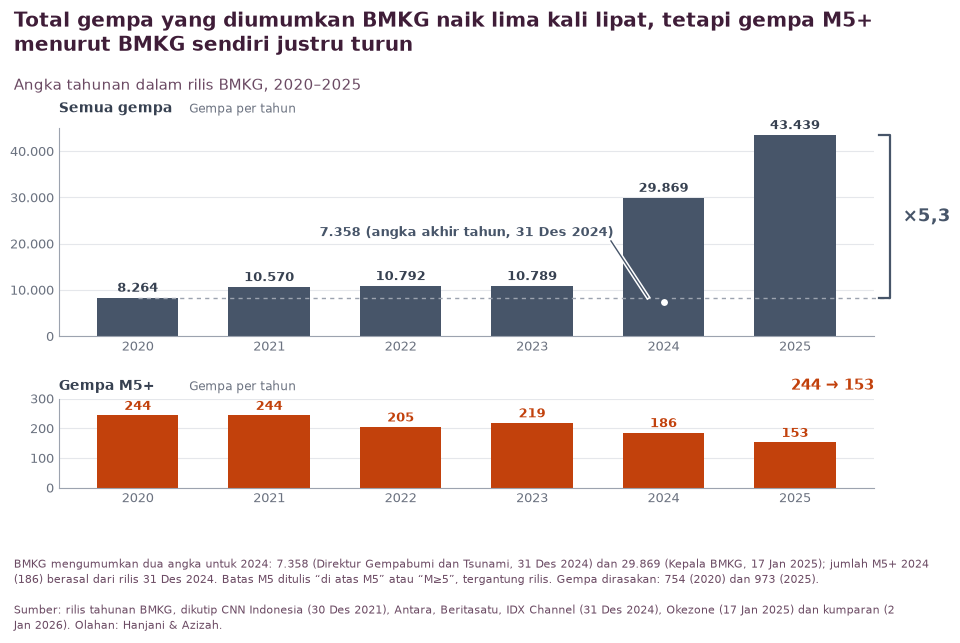

In [14]:
# G1: BMKG release totals (top) and M5+ (bottom)
d = FD["f1"]; yrs = [r["year"] for r in d["years"]]; xs = np.arange(len(yrs))
fig, (top, bot) = frame(
    "Total gempa yang diumumkan BMKG naik lima kali lipat, tetapi gempa M5+ menurut BMKG sendiri justru turun",
    "Angka tahunan dalam rilis BMKG, 2020–2025",
    "BMKG mengumumkan dua angka untuk 2024: 7.358 (Direktur Gempabumi dan Tsunami, 31 Des 2024) dan 29.869 (Kepala BMKG, 17 Jan 2025); "
    "jumlah M5+ 2024 (186) berasal dari rilis 31 Des 2024. Batas M5 ditulis “di atas M5” atau “M≥5”, tergantung rilis. "
    "Gempa dirasakan: 754 (2020) dan 973 (2025).",
    "Sumber: rilis tahunan BMKG, dikutip CNN Indonesia (30 Des 2021), Antara, Beritasatu, IDX Channel (31 Des 2024), Okezone (17 Jan 2025) "
    "dan kumparan (2 Jan 2026). Olahan: Hanjani & Azizah.", panels=2, ratios=[7, 3])
tot = [r["total"] for r in d["years"]]; m5 = [r["m5plus"] for r in d["years"]]
top.bar(xs, tot, width=0.62, color=COL["neutral"])
for x_, v in zip(xs, tot):
    top.text(x_, v + 700, id_int(v), ha="center", va="bottom", fontsize=9, fontweight="bold", color=COL["text"])
top.set_ylim(0, 45000); top.set_yticks(range(0, 45001, 10000)); yfmt(top)
top.set_xticks(xs, yrs); top.set_xlim(-0.6, len(yrs) - 0.4)
panel_title(top, "Semua gempa", "Gempa per tahun")
i24 = yrs.index(2024); alt = d["years"][i24]["total_alt"]
top.plot([i24 - 0.12, i24 - 0.4], [alt + 1100, 20600], color="white", lw=3.2, zorder=3)
top.plot([i24 - 0.12, i24 - 0.4], [alt + 1100, 20600], color=COL["neutral"], lw=1, zorder=4)
top.scatter([i24], [alt], s=46, facecolor="white", edgecolor=COL["neutral"], linewidth=1.8, zorder=5)
top.text(i24 - 0.38, 21000, "7.358 (angka akhir tahun, 31 Des 2024)", ha="right", va="bottom", fontsize=9, fontweight="bold", color=COL["neutral"])
bx = len(yrs) - 0.4 + 0.12
top.plot([0, bx], [tot[0], tot[0]], ls=(0, (3, 3)), color="#9CA3AF", lw=1, clip_on=False)
top.plot([bx - 0.08, bx, bx, bx - 0.08], [tot[0], tot[0], tot[-1], tot[-1]], color=COL["neutral"], lw=1.6, clip_on=False)
top.text(bx + 0.1, (tot[0] + tot[-1]) / 2, "×5,3", fontsize=13, fontweight="bold", color=COL["neutral"], va="center")
bot.bar(xs, m5, width=0.62, color=COL["strong"])
for x_, v in zip(xs, m5):
    bot.text(x_, v + 8, id_int(v), ha="center", va="bottom", fontsize=9, fontweight="bold", color=COL["strong"])
bot.set_ylim(0, 300); bot.set_yticks([0, 100, 200, 300]); yfmt(bot)
bot.set_xticks(xs, yrs); bot.set_xlim(-0.6, len(yrs) - 0.4)
panel_title(bot, "Gempa M5+", "Gempa per tahun")
bot.text(1, 1.06, "244 → 153", transform=bot.transAxes, ha="right", va="bottom", fontsize=11, fontweight="bold", color=COL["strong"])
save(fig, "g1")

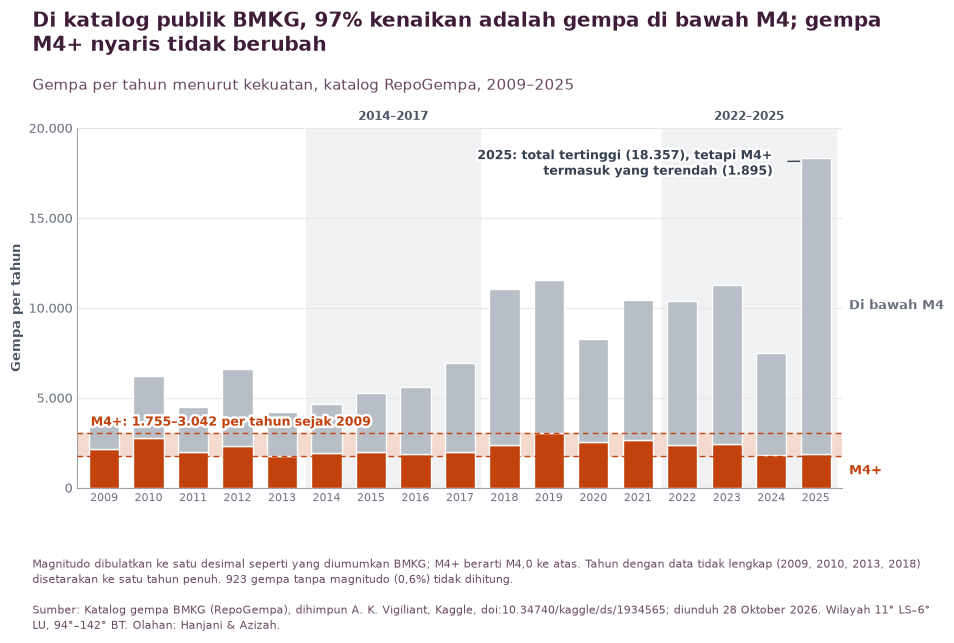

In [15]:
# G2: catalog quakes per year, stacked with M4+ at the base
d = FD["f2"]; yrs = [r["year"] for r in d["years"]]; xs = np.arange(len(yrs))
fig, (ax,) = frame(
    "Di katalog publik BMKG, 97% kenaikan adalah gempa di bawah M4; gempa M4+ nyaris tidak berubah",
    "Gempa per tahun menurut kekuatan, katalog RepoGempa, 2009–2025",
    "Magnitudo dibulatkan ke satu desimal seperti yang diumumkan BMKG; M4+ berarti M4,0 ke atas. Tahun dengan data tidak lengkap "
    "(2009, 2010, 2013, 2018) disetarakan ke satu tahun penuh. 923 gempa tanpa magnitudo (0,6%) tidak dihitung.",
    SOURCE_CATALOG, right=0.85)
m4 = np.array([r["m4plus"] for r in d["years"]]); b4 = np.array([r["below4"] for r in d["years"]])
for a, b, lab in [(2014, 2017, "2014–2017"), (2022, 2025, "2022–2025")]:
    ax.axvspan(yrs.index(a) - 0.45, yrs.index(b) + 0.45, color=COL["neutral8"], zorder=0)
    ax.text((yrs.index(a) + yrs.index(b)) / 2, 20300, lab, ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=COL["label"])
mn, mx = d["m4plus_min"]["value"], d["m4plus_max"]["value"]
ax.axhspan(mn, mx, color=COL["strong20"], zorder=0.5)
ax.bar(xs, m4, width=0.68, color=COL["strong"], edgecolor="white", linewidth=1, zorder=2)
ax.bar(xs, b4, bottom=m4, width=0.68, color=COL["small"], edgecolor="white", linewidth=1, zorder=2)
for v in (mn, mx):
    ax.axhline(v, color=COL["strong"], lw=1, ls=(0, (4, 3)), zorder=3)
ax.text(-0.3, mx + 250, "M4+: 1.755–3.042 per tahun sejak 2009", fontsize=9, fontweight="bold", color=COL["strong"], va="bottom", zorder=4, path_effects=HALO)
ax.set_ylim(0, 20000); ax.set_yticks(range(0, 20001, 5000)); yfmt(ax); ax.set_ylabel("Gempa per tahun")
ax.set_xticks(xs, yrs, rotation=0); ax.set_xlim(-0.6, len(yrs) - 0.4)
ax.tick_params(axis="x", labelsize=8)
r25 = d["years"][-1]
ax.text(len(yrs) - 0.4 + 0.15, r25["m4plus"] / 2, "M4+", color=COL["strong"], fontsize=9.5, fontweight="bold", va="center")
ax.text(len(yrs) - 0.4 + 0.15, r25["m4plus"] + r25["below4"] / 2, "Di bawah M4", color=COL["small_text"], fontsize=9.5, fontweight="bold", va="center")
ax.annotate("\n".join(textwrap.wrap("2025: total tertinggi (18.357), tetapi M4+ termasuk yang terendah (1.895)", 46)),
            xy=(len(yrs) - 1 - 0.36, r25["total"] - 200), xytext=(len(yrs) - 1.75, 18900), ha="right", va="top",
            fontsize=9, fontweight="bold", color=COL["text"], path_effects=HALO,
            arrowprops=dict(arrowstyle="-", color=COL["text"], lw=1, shrinkA=2, shrinkB=0))
save(fig, "g2")

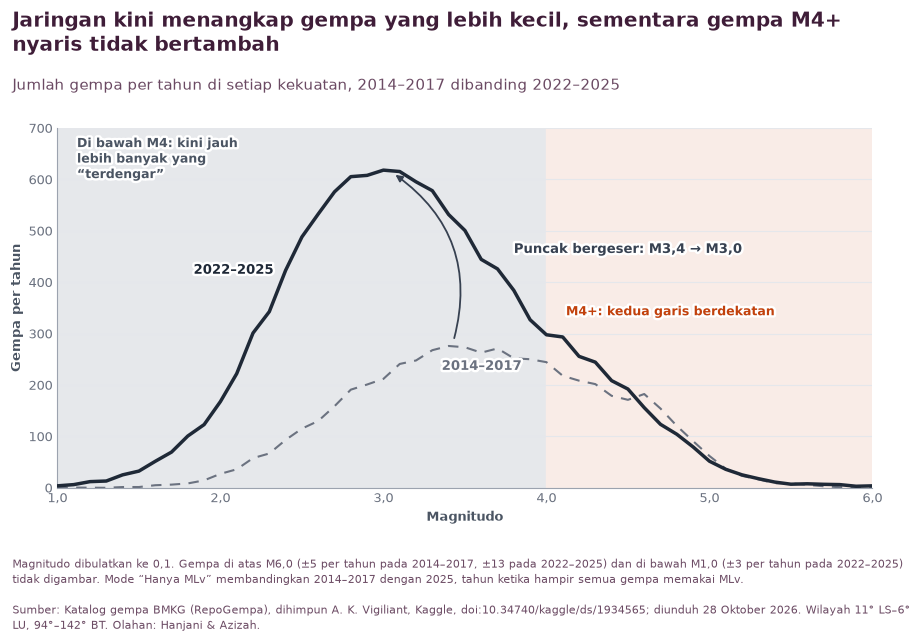

In [16]:
# G3: magnitude distribution per year, "Semua jenis magnitudo" (final state)
d = FD["f3"]
mA = np.array([p["m"] for p in d["all"]["A"]]); vA = np.array([p["per_year"] for p in d["all"]["A"]]); vB = np.array([p["per_year"] for p in d["all"]["B"]])
fig, (ax,) = frame(
    "Jaringan kini menangkap gempa yang lebih kecil, sementara gempa M4+ nyaris tidak bertambah",
    "Jumlah gempa per tahun di setiap kekuatan, 2014–2017 dibanding 2022–2025",
    "Magnitudo dibulatkan ke 0,1. Gempa di atas M6,0 (±5 per tahun pada 2014–2017, ±13 pada 2022–2025) dan di bawah M1,0 "
    "(±3 per tahun pada 2022–2025) tidak digambar. Mode “Hanya MLv” membandingkan 2014–2017 dengan 2025, tahun ketika hampir semua gempa memakai MLv.",
    SOURCE_CATALOG)
ax.axvspan(1, 4, color=COL["small35"], zorder=0); ax.axvspan(4, 6, color=COL["strong_tint"], zorder=0)
ax.plot(mA, vA, color=COL["small_text"], lw=1.5, ls=(0, (5, 4)), zorder=3)
ax.plot(mA, vB, color=COL["dark"], lw=2.5, zorder=3)
ax.set_xlim(1, 6); ax.set_ylim(0, 700); ax.set_yticks(range(0, 701, 100)); yfmt(ax)
ax.set_xticks(range(1, 7), [id_dec(m) for m in range(1, 7)]); ax.set_xlabel("Magnitudo"); ax.set_ylabel("Gempa per tahun")
ax.text(1.12, 685, "\n".join(textwrap.wrap("Di bawah M4: kini jauh lebih banyak yang “terdengar”", 26)), va="top", fontsize=9, fontweight="bold", color=COL["label"], path_effects=HALO)
ax.text(4.12, 330, "M4+: kedua garis berdekatan", va="bottom", fontsize=9, fontweight="bold", color=COL["strong"], path_effects=HALO)
pb = mA[vB.argmax()]; rise = next(m for m, v in zip(mA, vB) if m < pb and v >= 0.6 * vB.max())
ax.text(rise - 0.08, vB[list(mA).index(rise)], "2022–2025", ha="right", va="center", fontsize=9.5, fontweight="bold", color=COL["dark"], path_effects=HALO)
ax.text(3.6, vA[list(np.round(mA, 1)).index(3.6)] - 14, "2014–2017", ha="center", va="top", fontsize=9.5, fontweight="bold", color=COL["small_text"], path_effects=HALO)
pa = mA[vA.argmax()]
ax.annotate("", xy=(pb + 0.06, vB.max() - 6), xytext=(pa + 0.03, vA.max() + 10),
            arrowprops=dict(arrowstyle="-|>", color=COL["text"], lw=1.3, connectionstyle="arc3,rad=0.35"))
ax.text(pa + 0.4, (vA.max() + vB.max()) / 2 + 10, "Puncak bergeser: M3,4 → M3,0", fontsize=9.5, fontweight="bold", color=COL["text"], path_effects=HALO)
save(fig, "g3")

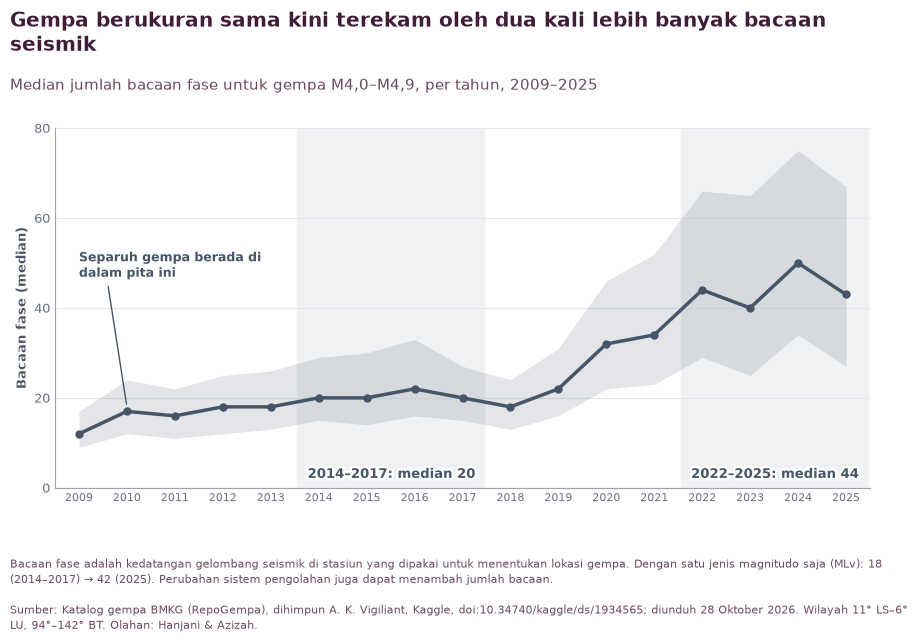

In [17]:
# G4: median phase readings for M4,0–4,9 quakes, with the IQR ribbon
d = FD["f4"]; yrs = np.array([r["year"] for r in d["years"]])
med = np.array([r["median"] for r in d["years"]]); q1 = np.array([r["q1"] for r in d["years"]]); q3 = np.array([r["q3"] for r in d["years"]])
fig, (ax,) = frame(
    "Gempa berukuran sama kini terekam oleh dua kali lebih banyak bacaan seismik",
    "Median jumlah bacaan fase untuk gempa M4,0–M4,9, per tahun, 2009–2025",
    "Bacaan fase adalah kedatangan gelombang seismik di stasiun yang dipakai untuk menentukan lokasi gempa. Dengan satu jenis magnitudo saja (MLv): "
    "18 (2014–2017) → 42 (2025). Perubahan sistem pengolahan juga dapat menambah jumlah bacaan.",
    SOURCE_CATALOG)
for a, b, lab in [(2014, 2017, f"2014–2017: median {id_int(d['median_A'])}"), (2022, 2025, f"2022–2025: median {id_int(d['median_B'])}")]:
    ax.axvspan(a - 0.45, b + 0.45, color=COL["neutral8"], zorder=0)
    ax.text((a + b) / 2, 1.5, lab, ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=COL["neutral"], path_effects=HALO, zorder=5)
ax.fill_between(yrs, q1, q3, color=COL["neutral"], alpha=0.15, lw=0, zorder=1)
ax.plot(yrs, med, color=COL["neutral"], lw=2.5, marker="o", ms=5, zorder=3)
ax.set_ylim(0, 80); ax.set_yticks(range(0, 81, 20)); ax.set_xlim(2008.5, 2025.5)
ax.set_xticks(yrs, yrs, fontsize=8); ax.set_ylabel("Bacaan fase (median)")
r10 = d["years"][1]
ax.annotate("Separuh gempa berada di\ndalam pita ini", xy=(2010, (r10["q1"] + r10["q3"]) / 2), xytext=(2009, 46), ha="left", va="bottom",
            fontsize=9, fontweight="bold", color=COL["neutral"], path_effects=HALO,
            arrowprops=dict(arrowstyle="-", color=COL["neutral"], lw=1, relpos=(0.15, 0)))
save(fig, "g4")

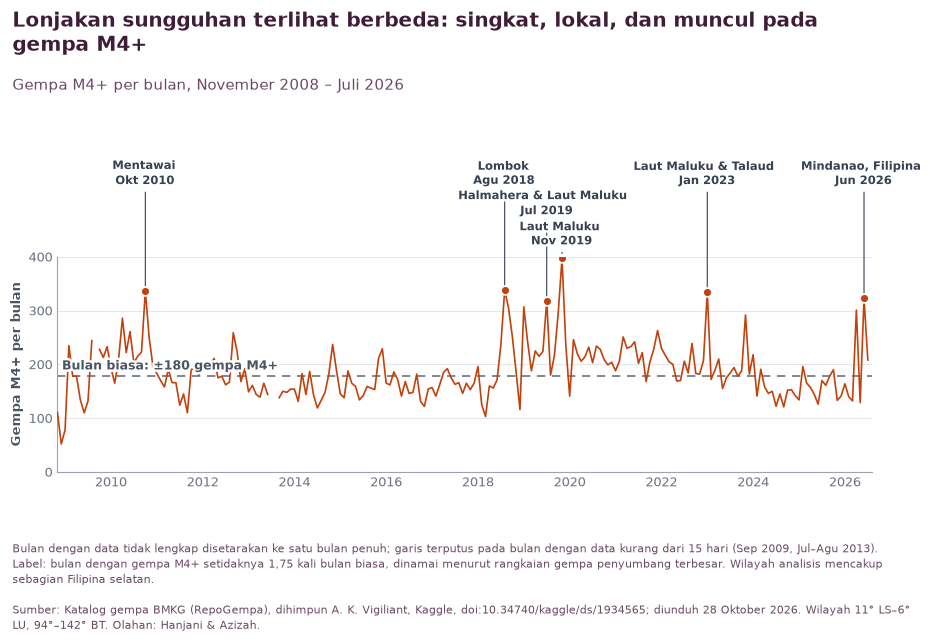

In [18]:
# G5: monthly M4+ with gaps, median line and the six labelled spikes
d = FD["f5"]
ms = [m for m in d["months"] if m["month"] <= d["last_month"]]
t = np.array([int(m["month"][:4]) + (int(m["month"][5:]) - 1) / 12 for m in ms])
v = np.array([np.nan if m["value"] is None else m["value"] for m in ms], dtype=float)
fig, (ax,) = frame(
    "Lonjakan sungguhan terlihat berbeda: singkat, lokal, dan muncul pada gempa M4+",
    "Gempa M4+ per bulan, November 2008 – Juli 2026",
    "Bulan dengan data tidak lengkap disetarakan ke satu bulan penuh; garis terputus pada bulan dengan data kurang dari 15 hari (Sep 2009, Jul–Agu 2013). "
    "Label: bulan dengan gempa M4+ setidaknya 1,75 kali bulan biasa, dinamai menurut rangkaian gempa penyumbang terbesar. "
    "Wilayah analisis mencakup sebagian Filipina selatan.",
    SOURCE_CATALOG, headroom=0.27)
ax.plot(t, v, color=COL["strong"], lw=1.2, zorder=3)
ax.axhline(d["median"], color=COL["small_text"], lw=1.2, ls=(0, (5, 4)), zorder=2)
ax.text(t[0] + 0.1, d["median"] + 6, "Bulan biasa: ±180 gempa M4+", fontsize=9, fontweight="bold", color=COL["label"], va="bottom", path_effects=HALO, zorder=5)
ax.set_ylim(0, 400); ax.set_yticks(range(0, 401, 100)); ax.set_xlim(t[0], t[-1] + 0.1)
ax.set_xticks(range(2010, 2027, 2), range(2010, 2027, 2)); ax.set_ylabel("Gempa M4+ per bulan")
tiers = {"2010-10": 0, "2018-08": 0, "2019-07": 1, "2019-11": 2, "2023-01": 0, "2026-06": 0}   # same tiers as the page at desktop width
for s in d["spikes"]:
    ts = int(s["month"][:4]) + (int(s["month"][5:]) - 1) / 12
    ax.scatter([ts], [s["value"]], s=40, color=COL["strong"], edgecolor="white", linewidth=1.2, zorder=4)
    ly = 1.04 + 0.14 * (2 - tiers[s["month"]])
    ax.annotate(f"{s['label']}\n{MONTHS[int(s['month'][5:]) - 1]} {s['month'][:4]}", xy=(ts, s["value"] + 9), xycoords="data",
                xytext=(ts, ly), textcoords=("data", "axes fraction"), annotation_clip=False, ha="center", va="bottom", fontsize=8.3, fontweight="bold",
                color=COL["text"], path_effects=HALO, arrowprops=dict(arrowstyle="-", color=COL["text"], lw=0.8, shrinkA=1, shrinkB=0))
save(fig, "g5")

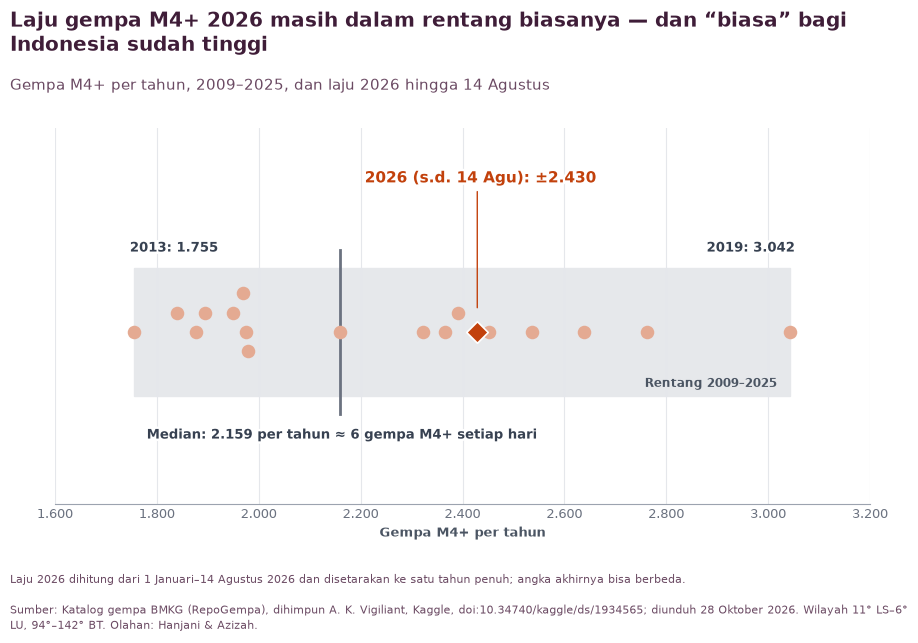

In [19]:
# G6: yearly M4+ dot strip, range band, median and the 2026 pace
d = FD["f6"]; vals = np.array([r["m4plus"] for r in d["years"]])
fig, (ax,) = frame(
    "Laju gempa M4+ 2026 masih dalam rentang biasanya — dan “biasa” bagi Indonesia sudah tinggi",
    "Gempa M4+ per tahun, 2009–2025, dan laju 2026 hingga 14 Agustus",
    "Laju 2026 dihitung dari 1 Januari–14 Agustus 2026 dan disetarakan ke satu tahun penuh; angka akhirnya bisa berbeda.",
    SOURCE_CATALOG)
ax.grid(False); ax.grid(axis="x", color=COL["grid"], linewidth=0.8)
ax.spines["left"].set_visible(False); ax.set_yticks([])
ax.set_xlim(1600, 3200); ax.set_ylim(-0.8, 0.95)
ax.set_xticks(range(1600, 3201, 200), [id_int(x_) for x_ in range(1600, 3201, 200)]); ax.set_xlabel("Gempa M4+ per tahun")
mn, mx = d["min"]["value"], d["max"]["value"]
ax.add_patch(plt.Rectangle((mn, -0.3), mx - mn, 0.6, color=COL["small35"], zorder=0))
ax.text(mx - 25, -0.27, "Rentang 2009–2025", ha="right", va="bottom", fontsize=8.5, fontweight="bold", color=COL["label"])
ax.plot([d["median"]] * 2, [-0.38, 0.38], color=COL["small_text"], lw=2, zorder=2)
ax.text(d["median"], -0.45, "Median: 2.159 per tahun ≈ 6 gempa M4+ setiap hari", ha="center", va="top", fontsize=9.5, fontweight="bold", color=COL["text"], path_effects=HALO)
# vertical jitter only where dots overlap (same rule as the page)
step_x = 1600 / (fig.get_size_inches()[0] * 0.815 * 72) * 15   # ≈ one dot diameter in data units
placed, ys = [], []
for x_ in vals:
    k = 0
    while True:
        off = 0 if k == 0 else (1 if k % 2 else -1) * ((k + 1) // 2) * 0.09
        if not any(abs(px - x_) < step_x and abs(po - off) < 0.085 for px, po in placed):
            break
        k += 1
    placed.append((x_, off)); ys.append(off)
ax.scatter(vals, ys, s=95, color=COL["strong45"], zorder=3, linewidth=0)
ax.text(mn - 8, 0.36, "2013: 1.755", ha="left", va="bottom", fontsize=9.5, fontweight="bold", color=COL["text"], path_effects=HALO)
ax.text(mx + 8, 0.36, "2019: 3.042", ha="right", va="bottom", fontsize=9.5, fontweight="bold", color=COL["text"], path_effects=HALO)
ax.scatter([d["pace_2026"]], [0], marker="D", s=120, color=COL["strong"], edgecolor="white", linewidth=1.2, zorder=4)
ax.annotate("2026 (s.d. 14 Agu): ±2.430", xy=(d["pace_2026"], 0.1), xytext=(d["pace_2026"], 0.68), ha="center", va="bottom",
            fontsize=11, fontweight="bold", color=COL["strong"], path_effects=HALO,
            arrowprops=dict(arrowstyle="-", color=COL["strong"], lw=1))
save(fig, "g6")

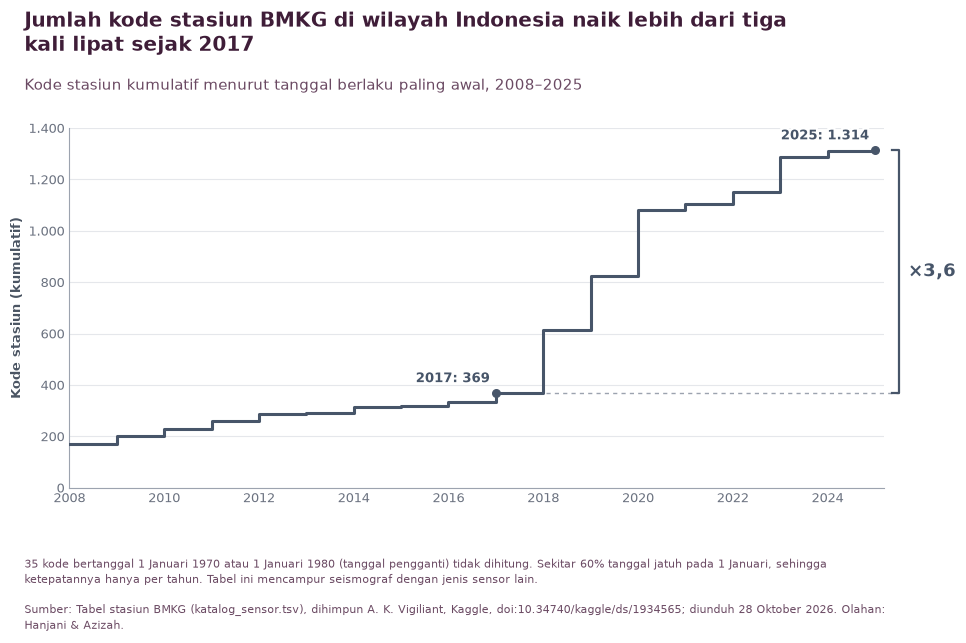

g1.png     173,242 bytes  sha256 24cf41465052bd81
g1.svg     118,437 bytes  sha256 1e9999c75cffdd15
g2.png     187,026 bytes  sha256 0bbd292b73120b90
g2.svg     242,461 bytes  sha256 5310db375a4a964a
g3.png     228,108 bytes  sha256 8032994093059be7
g3.svg     246,718 bytes  sha256 ec1d1bedf41b9bc8
g4.png     178,913 bytes  sha256 3326eae6b0bee992
g4.svg     197,101 bytes  sha256 bd0793c8da3df487
g5.png     236,634 bytes  sha256 959ec20dc766cd6a
g5.svg     305,460 bytes  sha256 d9fc0abe93a0860a
g6.png     135,781 bytes  sha256 694ede0378bee431
g6.svg     201,373 bytes  sha256 dfa399ddd557f023
gx.png     132,974 bytes  sha256 42b42a60356e9829
gx.svg     118,186 bytes  sha256 08aaa5c831c179c5


In [20]:
# GX (discarded, appendix): cumulative station codes
d = FD["fx"]; yrs = np.array([r["year"] for r in d["years"]]); codes = np.array([r["codes"] for r in d["years"]])
fig, (ax,) = frame(
    "Jumlah kode stasiun BMKG di wilayah Indonesia naik lebih dari tiga kali lipat sejak 2017",
    "Kode stasiun kumulatif menurut tanggal berlaku paling awal, 2008–2025",
    "35 kode bertanggal 1 Januari 1970 atau 1 Januari 1980 (tanggal pengganti) tidak dihitung. Sekitar 60% tanggal jatuh pada 1 Januari, "
    "sehingga ketepatannya hanya per tahun. Tabel ini mencampur seismograf dengan jenis sensor lain.",
    "Sumber: Tabel stasiun BMKG (katalog_sensor.tsv), dihimpun A. K. Vigiliant, Kaggle, doi:10.34740/kaggle/ds/1934565; diunduh 28 Oktober 2026. Olahan: Hanjani & Azizah.")
ax.step(yrs, codes, where="post", color=COL["neutral"], lw=2.2, zorder=3)
c17, c25 = d["y2017"], d["y2025"]
ax.scatter([2017, 2025], [c17, c25], s=30, color=COL["neutral"], zorder=4)
ax.text(2016.85, c17 + 30, "2017: 369", ha="right", va="bottom", fontsize=9.5, fontweight="bold", color=COL["neutral"], path_effects=HALO)
ax.text(2024.85, c25 + 30, "2025: 1.314", ha="right", va="bottom", fontsize=9.5, fontweight="bold", color=COL["neutral"], path_effects=HALO)
bx = 2025.5
ax.plot([2017, bx], [c17, c17], ls=(0, (3, 3)), color="#9CA3AF", lw=1, clip_on=False)
ax.plot([bx - 0.15, bx, bx, bx - 0.15], [c17, c17, c25, c25], color=COL["neutral"], lw=1.6, clip_on=False)
ax.text(bx + 0.2, (c17 + c25) / 2, "×3,6", fontsize=13, fontweight="bold", color=COL["neutral"], va="center")
ax.set_xlim(2008, 2025.2); ax.set_ylim(0, 1400); ax.set_yticks(range(0, 1401, 200)); yfmt(ax)
ax.set_xticks(range(2008, 2026, 2), range(2008, 2026, 2)); ax.set_ylabel("Kode stasiun (kumulatif)")
save(fig, "gx")

for p in sorted(EXPORTS.iterdir()):
    print(f"{p.name:8s} {p.stat().st_size:>9,} bytes  sha256 {sha256(p)[:16]}")

## 12. Verifikasi

Setiap nilai di `data/expected_numbers.json` dibandingkan dengan hasil notebook ini. Bilangan bulat, teks, dan nilai benar/salah harus sama persis; bilangan desimal boleh berbeda paling banyak ±0,05. Setelah itu setiap `site/data/*.json` dibandingkan nilainya dengan data rujukan `data/figure_data/*.json`.

Jika ada ✗, notebook berhenti di sel terakhir. Angka tidak boleh "diperbaiki" agar cocok: selisih harus dilaporkan.

In [21]:
def flatten(x, prefix=""):
    if isinstance(x, dict):
        for key, v in x.items():
            yield from flatten(v, f"{prefix}.{key}" if prefix else str(key))
    elif isinstance(x, list):
        for i, v in enumerate(x):
            yield from flatten(v, f"{prefix}[{i}]")
    else:
        yield prefix, x


def same(expected, got, tol=0.05):
    if isinstance(expected, float) and not isinstance(got, bool) and isinstance(got, (int, float)):
        return abs(expected - got) <= tol
    return type(expected) is type(got) and expected == got


expected = dict(flatten(json.loads(EXPECTED.read_text())))
computed = dict(flatten(json.loads(json.dumps(R, ensure_ascii=False))))
table = pd.DataFrame([dict(nilai=key, diharapkan=exp, hasil=computed.get(key, "(tidak ada)"),
                           cek="✓" if key in computed and same(exp, computed[key]) else "✗")
                      for key, exp in expected.items()])
extra = sorted(set(computed) - set(expected))
print(f"{(table.cek == '✓').sum()} ✓ · {(table.cek == '✗').sum()} ✗ dari {len(table)} nilai"
      + (f" · nilai tambahan tanpa rujukan: {extra}" if extra else ""))
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60):
    display(table)

178 ✓ · 0 ✗ dari 178 nilai


,nilai,diharapkan,hasil,cek
0,events_in_box,144030,144030,✓
1,events_without_magnitude,923,923,✓
2,broken_days,143,143,✓
3,F2.period_A.total,5614,5614,✓
4,F2.period_A.below4,3670,3670,✓
5,F2.period_A.m4plus,1944,1944,✓
6,F2.period_A.m5plus,173,173,✓
7,F2.period_A.m6plus,6,6,✓
8,F2.period_B.total,11875,11875,✓
9,F2.period_B.below4,9730,9730,✓


In [22]:
def same_values(a, b, tol=0.05):
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_values(a[x], b[x], tol) for x in a)
    if isinstance(a, list):
        return isinstance(b, list) and len(a) == len(b) and all(same_values(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, float) or isinstance(b, float):
        return a is not None and b is not None and abs(a - b) <= tol
    return a == b


files = pd.DataFrame([dict(berkas=f"{n}.json",
                           nilai_sama="✓" if same_values(json.loads((REFERENCE_FIG / f"{n}.json").read_text()),
                                                         json.loads((SITE_DATA / f"{n}.json").read_text())) else "✗",
                           byte_sama="✓" if (REFERENCE_FIG / f"{n}.json").read_bytes() == (SITE_DATA / f"{n}.json").read_bytes() else "–")
                      for n in ("f1", "f2", "f3", "f4", "f5", "f6", "fx")])
display(files)

assert (table.cek == "✓").all(), "a number differs from expected_numbers.json: stop and report, do not patch"
assert (files.nilai_sama == "✓").all(), "figure data differs from data/figure_data: stop and report"
print("Semua angka dan data gambar cocok dengan rujukan.")

,berkas,nilai_sama,byte_sama
0,f1.json,✓,✓
1,f2.json,✓,✓
2,f3.json,✓,✓
3,f4.json,✓,✓
4,f5.json,✓,✓
5,f6.json,✓,✓
6,fx.json,✓,✓


Semua angka dan data gambar cocok dengan rujukan.
